# Netflix movies from the 1990s

This exploratory analysis uses the dataset supplied with DataCamp's [Investigating Netflix Movies](https://www.datacamp.com/projects/1674) project. It examines the distribution of movie runtimes and counts action movies shorter than 90 minutes.

The sample includes entries labeled `Movie` with release years from 1990 through 1999. Runtimes are measured in minutes.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

netflix = pd.read_csv("netflix_data.csv")
movies = netflix.loc[
    netflix["type"].eq("Movie") & netflix["release_year"].between(1990, 1999)
].copy()
runtimes = movies["duration"].dropna()

print(f"Movies released from 1990 through 1999: {len(movies)}")
print(f"Movies with a recorded runtime: {len(runtimes)}")

Movies released from 1990 through 1999: 183
Movies with a recorded runtime: 183


## Runtime distribution

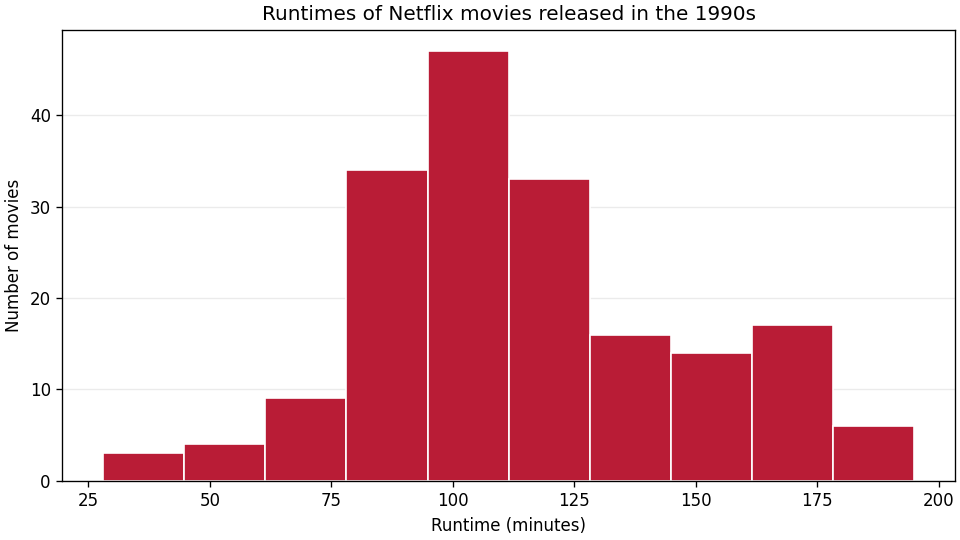

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.hist(runtimes, bins=10, color="#b91c36", edgecolor="white")
ax.set(
    title="Runtimes of Netflix movies released in the 1990s",
    xlabel="Runtime (minutes)",
    ylabel="Number of movies",
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
plt.show()

In [3]:
most_common_durations = runtimes.mode()
duration = int(most_common_durations.iloc[0])
short_action_movies = movies["genre"].eq("Action") & movies["duration"].lt(90)
short_movie_count = int(short_action_movies.sum())

modes = ", ".join(str(int(minutes)) for minutes in most_common_durations)
print(f"Most frequent runtime(s) in minutes: {modes}")
print(f"Action movies under 90 minutes: {short_movie_count}")

Most frequent runtime(s) in minutes: 94
Action movies under 90 minutes: 7


## Findings

- The most frequent exact runtime was **94 minutes** across the **183 movies** in this sample.
- **7 movies** had the dataset's `Action` label and ran for less than 90 minutes.

These findings describe the supplied sample of Netflix titles.